# 2 · Metabolism: Human-GEM constrained by the simulated proteome

**Why flux balance analysis.** Human metabolic *stoichiometry* is known genome-wide (Human-GEM: 12,748 reactions
in 8 compartments); kinetic constants are not. FBA needs only stoichiometry. On its own it has no dynamics and
ignores the rest of the cell, so here each enzyme-catalysed reaction gets a capacity that follows the abundance of
its enzyme, calibrated on a reference state that reproduces measured growth and exchange rates.

Calibration steps (all in `Metabolism._calibrate`):
1. pin growth (22 h doubling), glucose uptake, lactate secretion, glutamine uptake and maintenance ATP to measured values;
2. close reactions whose enzyme is not detected in HeLa, unless the pinned state needs them;
3. take the minimal-total-flux state as the reference;
4. give each reaction a capacity of twice its reference flux, scaled by enzyme abundance.

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from humancell import data, plotting as P; P.style()
from humancell.metabolism import Metabolism

g = data.build_gene_table("HeLa")
met = Metabolism(g, verbose=True)
print(f"{met.n:,} reactions, {len(met.gpr):,} enzyme-catalysed, {len(met.gene_ids):,} genes; "
      f"{len(met.closed):,} closed (enzyme not expressed), {len(met.gapfilled)} kept without detected enzyme")

1518 of 7746 enzyme-catalysed reactions have no detectable enzyme
Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


closed 1498, kept 20 undetected-enzyme reactions required for growth


reference: mu=0.0315/h, mu_max=0.0411/h
12,748 reactions, 7,746 enzyme-catalysed, 2,870 genes; 1,498 closed (enzyme not expressed), 20 kept without detected enzyme


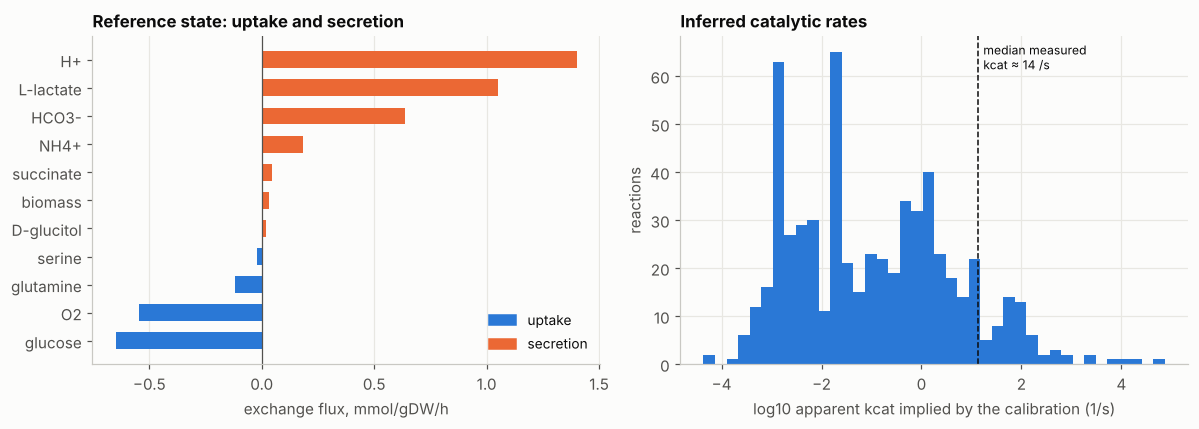

median apparent kcat 0.08 /s over 604 flux-carrying reactions


In [2]:
ref = pd.Series({k: met.v_ref[i] for k, i in met.exchange.items()})
ref = ref[ref.abs() > 0.02].sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.barh(ref.index, ref.values, color=[P.SERIES[0] if v < 0 else P.SERIES[1] for v in ref.values], height=0.6)
ax.axvline(0, color=P.MUTED, lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("exchange flux, mmol/gDW/h"); ax.set_title("Reference state: uptake and secretion")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=P.SERIES[0]), plt.Rectangle((0, 0), 1, 1, color=P.SERIES[1])], ["uptake", "secretion"], loc="lower right")
ax = axes[1]
k = np.array(list(met.kcat_app.values())); k = k[k > 0]
ax.hist(np.log10(k), bins=40, color=P.SERIES[0])
ax.axvline(np.log10(13.7), color=P.INK, lw=1, ls="--"); ax.text(np.log10(13.7) + 0.1, ax.get_ylim()[1] * 0.9, "median measured\nkcat ≈ 14 /s", fontsize=8)
ax.set_xlabel("log10 apparent kcat implied by the calibration (1/s)"); ax.set_ylabel("reactions"); ax.set_title("Inferred catalytic rates")
plt.tight_layout(); plt.show()
print(f"median apparent kcat {np.median(k):.2f} /s over {len(k)} flux-carrying reactions")

The reference state shows aerobic glycolysis (lactate secreted at 1.6× glucose uptake) because that ratio is
pinned to measurement, not predicted. The apparent kcat values are *inferred* and sit well below typical
in-vitro kcat (median ≈ 14 /s): enzymes in vivo are unsaturated, and proteomics counts all isoforms. They are
effective parameters of this model, not enzyme constants.

## Predictions: environment changes
Nothing below was fitted. Each row changes the medium and re-solves.

In [3]:
def state(label, **medium):
    met.set_medium(**medium)
    r = met.solve(mu_demand=met.mu_ref)
    ex = r["exchange"]
    return dict(condition=label, max_growth_per_h=round(r["mu_cap"], 4), ATP_capacity=round(r["atp_cap"], 2),
                glucose_uptake=round(-ex.get("glucose", 0), 2), lactate_out=round(ex.get("L-lactate", 0), 2),
                O2_uptake=round(-ex.get("O2", 0), 2), glutamine_uptake=round(-ex.get("glutamine", 0), 2))
base = dict(glucose=25.0, O2=0.2, glutamine=4.0, leucine=0.4)
rows = [state("reference medium", **base), state("anoxia", **{**base, "O2": 0.0}),
        state("no glucose", **{**base, "glucose": 0.0}), state("no glutamine", **{**base, "glutamine": 0.0}),
        state("no leucine (essential)", **{**base, "leucine": 0.0})]
met.set_medium(**base)
pd.DataFrame(rows).set_index("condition")

,max_growth_per_h,ATP_capacity,glucose_uptake,lactate_out,O2_uptake,glutamine_uptake
condition,,,,,,
reference medium,0.0411,7.06,0.65,1.05,0.55,0.12
anoxia,0.0000,2.50,0.99,1.56,0.00,0.06
no glucose,0.0310,4.64,0.00,0.00,0.82,0.21
no glutamine,0.0411,7.06,0.65,1.05,0.57,0.00
no leucine (essential),-0.0000,7.06,0.65,1.05,0.55,0.12


* **Anoxia**: growth capacity falls to zero while ATP is still available from glycolysis (lactate rises). The
  model's reason: sterol and unsaturated-lipid synthesis need O₂ and this medium carries almost no lipid.
* **No leucine**: no growth, as expected for an essential amino acid; glutamine is dispensable here because
  glutamate and other amino acids substitute.
* **No glucose**: the network can still grow on amino acids. Real HeLa cells grow poorly without a hexose,
  so FBA is too permissive here; this is a known limitation of stoichiometric models.

## Which biomass precursor fails?

In [4]:
pd.Series(met.pool_capacities(), name="growth rate each pool alone could sustain (1/h)").round(3).to_frame()

,growth rate each pool alone could sustain (1/h)
protein,0.059
RNA,0.063
DNA,0.063
lipid,0.043
cofactor,0.041
metabolite,0.063
glycogen,0.063


## Single-gene deletions across all metabolic genes

In [5]:
inv = {v: k for k, v in g.symbol.to_dict().items()}
sym = g.symbol.to_dict()
ko = pd.Series({sym[x]: met.knockout([x]) for x in met.gene_ids if x in sym and g.protein[x] > 0})
ceg, neg = data.essential_sets()
tab = pd.DataFrame({"genes": [len(ko), int((ko < 0.5).sum()), int(ko.index.isin(ceg).sum()), int(((ko < 0.5) & ko.index.isin(ceg)).sum())]},
                   index=["expressed metabolic genes", "predicted essential (growth < 50%)", "of which core-essential in CRISPR screens (CEGv2)", "predicted essential AND core-essential"])
print("examples predicted essential:", ", ".join(sorted(ko[ko < 0.5].index)[:40]), "...")
tab

examples predicted essential: AARS1, ACAA2, ACACA, ACADL, ACADSB, ADSL, ADSS2, AHCTF1, ALAD, ALDH9A1, AMACR, ATIC, ATP5F1A, ATP5F1B, ATP5F1C, ATP5F1D, ATP5F1E, ATP5MC1, ATP5MC2, ATP5MC3, ATP5ME, ATP5MF, ATP5MG, ATP5MGL, ATP5MJ, ATP5MK, ATP5PB, ATP5PD, ATP5PF, ATP5PO, CAD, CARS1, CDIPT, CDS2, CEPT1, CMPK1, COASY, COQ2, COQ3, COQ6 ...


,genes
expressed metabolic genes,2101
predicted essential (growth < 50%),222
of which core-essential in CRISPR screens (CEGv2),119
predicted essential AND core-essential,52


Metabolism alone finds essential biosynthetic enzymes (nucleotide, sterol, lipid synthesis) but, as every
FBA model, misses genes whose loss is rescued on paper by an alternative route. Notebook 6 scores the
*integrated* model against CRISPR data.